# Boréal Marché — project walkthrough (Sprint 1: D1–D3)

**Olga Morgunova · 420-977-VA Capstone 1**

This notebook is the *narrative* view of the project. All business logic lives in `src/boreal_marche/`;
the notebook only **imports** it, reads the pipeline outputs and draws the key results
(assignment §7.2: "notebooks — narrative and exploration only; they import from `src/`").

| Section | What it shows |
|---|---|
| 1 | Setup and (optional) pipeline run |
| 2 | Data provenance and cleaning |
| 3 | Exploratory analysis |
| 4 | Observation / label windows and the feature table |
| 5 | Leakage checks |
| 6 | Head A: spot-check, tuning, calibration, profit threshold, test results, error analysis |
| 7 | Head B: association rules and the serving engine |
| 8 | The typed API, called in-process |
| 9 | MLflow tracking summary |

### How to run it

```bash
# once: environment with the notebook tools (Linux/macOS; Windows: .venv\Scripts\python ...)
make setup-pinned                    # or: uv pip install -r requirements-dev.txt && uv pip install -e . --no-deps
python scripts/run.py all            # builds data/, artifacts/, reports/metrics/ (~12 min)
# open interactively
.venv/bin/jupyter lab notebooks/01_project_walkthrough.ipynb
# or re-execute headless and save outputs in the file
python scripts/run.py notebook
```

**Test-set protection.** Section 6.5 *reads* the recorded test evaluation
(`reports/metrics/test_evaluation.json`); it never re-scores the test snapshot.

## 1. Setup

In [1]:
# Standard imports + the project package (installed in editable mode, or found via src/ on sys.path).
import json
import os
import subprocess
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":  # started from notebooks/ -> go to the repository root
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault(
    "BOREAL_MODEL_SOURCE", "local"
)  # serve the committed artifact, no MLflow needed

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from boreal_marche.config import Paths, load_params
from boreal_marche.reporting import style  # one visual system for every chart (validated palette)

# style.py selects the headless "Agg" backend for report PNGs; switch back to inline plots here
# and re-apply the palette (the inline backend resets a few rcParams).
%matplotlib inline
style.apply()

pd.set_option(
    "display.max_columns", 30, "display.width", 160, "display.float_format", "{:,.4f}".format
)
params, paths = load_params(), Paths(ROOT)
M = paths.metrics


def metric(name: str) -> dict:
    # Read one pipeline output from reports/metrics/.
    return json.loads((M / f"{name}.json").read_text(encoding="utf-8"))


print("repository:", ROOT)
print("python    :", sys.version.split()[0])

repository: /home/master/AI/projects/boreal-marche-capstone
python    : 3.11.16


### 1.1 Are the pipeline outputs present?

The notebook needs the data layers (`data/silver`, `data/gold`) and the artifacts. On a fresh clone set
`RUN_PIPELINE = True` (or run `python scripts/run.py all` in a terminal): the cell calls the same
cross-platform task runner that the Makefile uses.

In [2]:
RUN_PIPELINE = False  # True -> run the whole offline pipeline from this notebook (~12 min)

required = {
    "silver lines": paths.silver_lines,
    "gold snapshots": paths.gold / "retention.parquet",
    "model artifact": paths.model_file,
    "rules artifact": paths.rules_file,
    "spot-check metrics": M / "spotcheck.json",
}
missing = [k for k, p in required.items() if not p.exists()]
if missing and RUN_PIPELINE:
    subprocess.run([sys.executable, "scripts/run.py", "all"], check=True, cwd=ROOT)
    missing = [k for k, p in required.items() if not p.exists()]
print("missing:", missing or "nothing — all outputs present")
assert not missing, "run `python scripts/run.py all` first (or set RUN_PIPELINE = True)"

missing: nothing — all outputs present


## 2. Data provenance and cleaning

`make data` downloads the UCI workbook (or uses a local copy), **verifies its SHA-256** against
`params.yaml`, converts both sheets to Parquet with an explicit schema and writes this manifest.
The data are public UCI Online Retail II, *re-skinned* as Boréal Marché — not client data.

In [3]:
manifest = json.loads(paths.manifest.read_text(encoding="utf-8"))
pd.Series(
    {
        k: manifest[k]
        for k in [
            "dataset",
            "doi",
            "licence",
            "sha256",
            "row_count",
            "sheet_row_counts",
            "date_min",
            "date_max",
            "acquisition",
        ]
    },
    name="value",
).to_frame()

,value
dataset,UCI Online Retail II
doi,10.24432/C5CG6D
licence,CC BY 4.0
sha256,bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4a...
row_count,1067371
sheet_row_counts,"{'Year 2009-2010': 525461, 'Year 2010-2011': 5..."
date_min,2009-12-01 07:45:00
date_max,2011-12-09 12:50:00
acquisition,existing data/raw copy


Eleven ordered cleaning rules; each records rows before/after and **why it exists**
(`src/boreal_marche/data/cleaning.py`). R10 does not delete rows: it defines the Head A view
(customers with an id); guest invoices stay available for Head B.

,rule,rows_before,rows_after,rows_removed,rows_flagged
0,R0 normalise codes,"1,067,371","1,067,371",0,0
1,R1 drop sheet overlap,"1,067,371","1,044,848","22,523",0
2,R2 drop exact duplicate lines,"1,044,848","1,033,034","11,814",0
3,R3 separate cancellations,"1,033,034","1,013,930","19,104",0
4,R4 drop bad-debt adjustments,"1,013,930","1,013,924",6,0
5,R5 drop non-positive quantity,"1,013,924","1,010,531","3,393",0
6,R6 drop non-positive price,"1,010,531","1,007,910","2,621",0
7,R7 drop service / fee SKUs,"1,007,910","1,003,338","4,572",0
8,R8 canonicalise descriptions,"1,003,338","1,003,338",0,"58,116"
9,R9 flag + cap outliers,"1,003,338","1,003,338",0,"1,642"


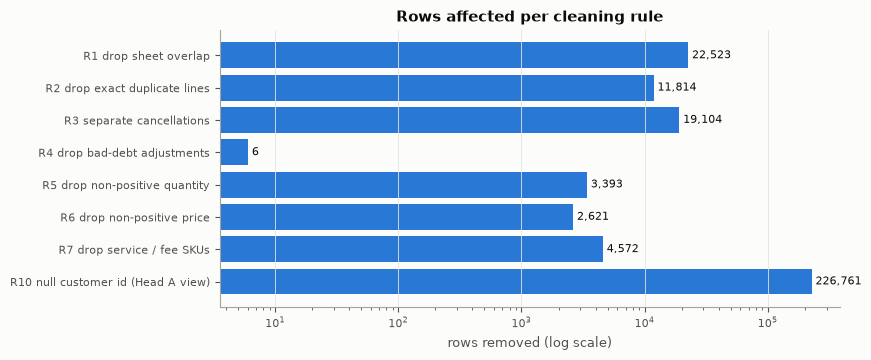

In [4]:
clean = metric("cleaning_report")
rules = pd.DataFrame(clean["rules"])[
    ["rule", "rows_before", "rows_after", "rows_removed", "rows_flagged"]
]
display(rules.style.format({c: "{:,}" for c in rules.columns if c != "rule"}))

removed = rules[rules["rows_removed"] > 0]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(removed["rule"][::-1], removed["rows_removed"][::-1], color=style.BLUE)
for i, v in enumerate(removed["rows_removed"][::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("rows removed (log scale)")
ax.set_title("Rows affected per cleaning rule")
ax.grid(axis="y", visible=False)
plt.show()

**Comment.** The largest single effect is **R1 — the two yearly sheets overlap for
2010-12-01…09 (22,523 lines)**. The original `scripts/etl.py` concatenated the sheets and would have
double-counted those orders. Cancellations (R3) are *separated*, never netted against the original
invoice: netting would delete a pre-cutoff purchase because of a post-cutoff event (leakage, §5).

## 3. Exploratory analysis (computed live from the silver layer)

1,003,338 clean lines · 39,516 invoices · 4,724 SKUs · 5,852 customers


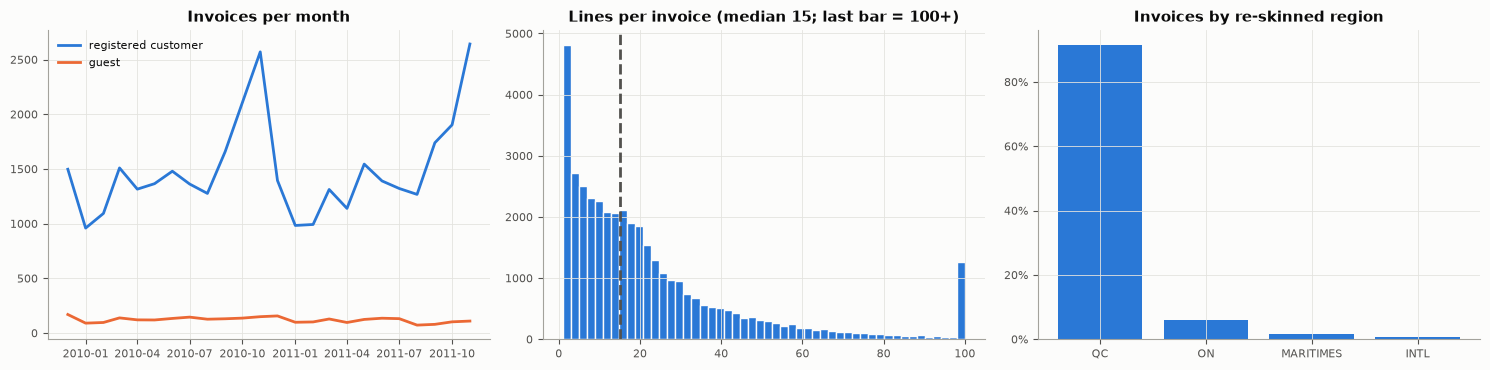

In [5]:
lines = pd.read_parquet(paths.silver_lines)
invoices = lines.groupby("invoice").agg(
    date=("invoice_date", "min"),
    guest=("has_customer", lambda s: not s.iloc[0]),
    n_lines=("stock_code", "size"),
    revenue=("line_revenue", "sum"),
    region=("region", "first"),
)
print(
    f"{len(lines):,} clean lines · {len(invoices):,} invoices · {lines['stock_code'].nunique():,} SKUs · "
    f"{lines.loc[lines['has_customer'], 'customer_id'].nunique():,} customers"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
monthly = (
    invoices[invoices["date"] < "2011-12-01"]
    .groupby([invoices["date"].dt.to_period("M"), "guest"])
    .size()
    .unstack(fill_value=0)
)
x = monthly.index.to_timestamp()
axes[0].plot(x, monthly[False], color=style.BLUE, label="registered customer")
axes[0].plot(x, monthly[True], color=style.ORANGE, label="guest")
axes[0].set_title("Invoices per month")
axes[0].legend()
axes[1].hist(
    invoices["n_lines"].clip(upper=100), bins=50, color=style.BLUE, edgecolor=style.SURFACE
)
axes[1].axvline(invoices["n_lines"].median(), color=style.INK_2, ls="--")
axes[1].set_title(f"Lines per invoice (median {invoices['n_lines'].median():.0f}; last bar = 100+)")
share = invoices["region"].value_counts(normalize=True)
axes[2].bar(share.index, share.values, color=style.BLUE)
axes[2].set_title("Invoices by re-skinned region")
axes[2].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

**Comment.** Strong Q4 seasonality (the retailer's peak) — this is why the label base rate moves
between cut-offs (§4). Baskets are large (wholesale-like buyers), which makes association rules
meaningful. ~92% of volume is the home market (QC after re-skinning), so regional subgroups are small.

## 4. Windows and the point-in-time feature table

For a cutoff *T*: features use only rows **before T** (180-day observation window + lifetime history),
the label is "≥ 1 order in [T, T+90 d)". Cut-offs are declared in `params.yaml`, not in a notebook cell.

observation: 180 days · label: 90 days
train: ['2010-06-01', '2010-09-01', '2010-12-01', '2011-03-01'] | validation: ['2011-06-01'] | test: ['2011-09-01']


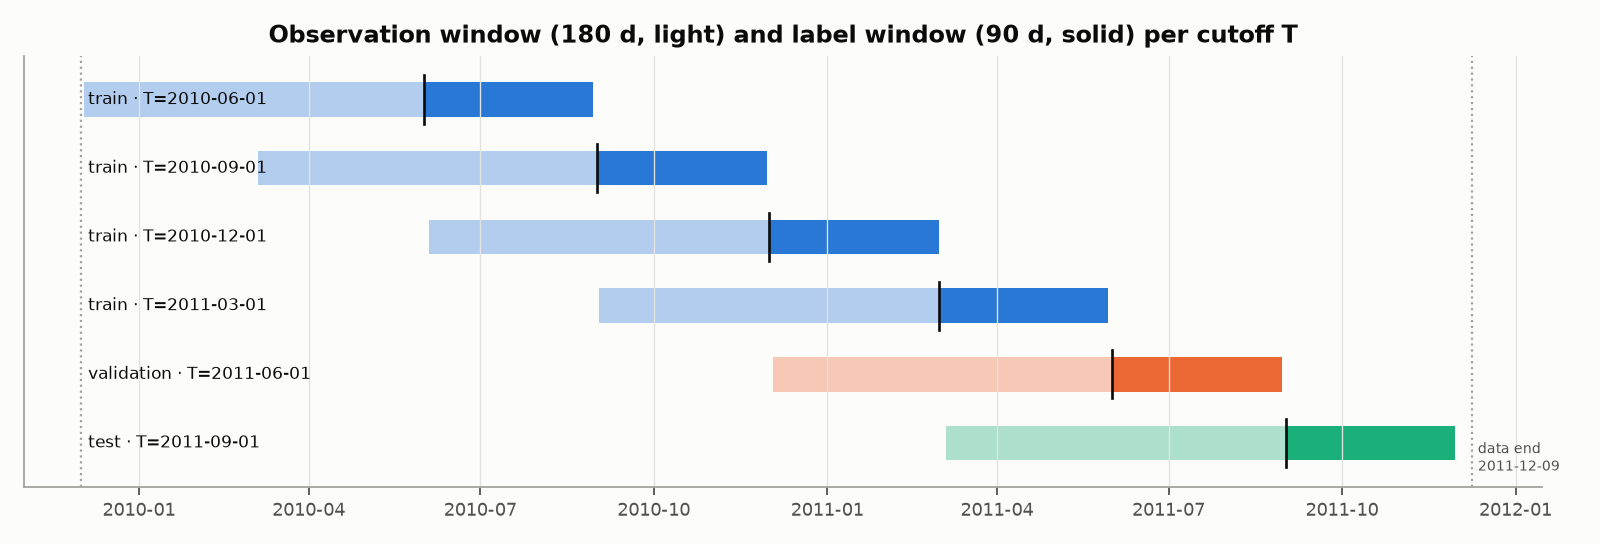

,split,cutoff,customers,return_rate
1,train,2010-06-01 00:00:00,"2,652",50.0%
2,train,2010-09-01 00:00:00,"2,822",62.0%
3,train,2010-12-01 00:00:00,"3,465",38.0%
4,train,2011-03-01 00:00:00,"3,338",42.4%
5,validation,2011-06-01 00:00:00,"2,658",50.0%
0,test,2011-09-01 00:00:00,"2,768",60.7%


In [6]:
w = params.windows
print("observation:", w.observation_days, "days · label:", w.label_days, "days")
print("train:", w.cutoffs.train, "| validation:", w.cutoffs.validation, "| test:", w.cutoffs.test)
display(Image(filename=str(paths.figures / "windows.png"), width=900))

gold = pd.read_parquet(paths.gold / "retention.parquet")
snap = (
    gold.groupby(["split", "cutoff"])
    .agg(customers=("customer_id", "size"), return_rate=("y", "mean"))
    .reset_index()
    .sort_values("cutoff")
)
display(snap.style.format({"return_rate": "{:.1%}", "customers": "{:,}"}))

In [7]:
from boreal_marche.features import FEATURE_SPEC, FEATURES

spec = pd.DataFrame([f.__dict__ for f in FEATURE_SPEC])
print(len(FEATURES), "features in", spec["family"].nunique(), "families")
missing_share = gold[FEATURES].isna().mean()
display(
    spec.assign(missing=spec["name"].map(missing_share))[
        ["name", "family", "dtype", "definition", "missing"]
    ].style.format({"missing": "{:.1%}"})
)

37 features in 9 families


,name,family,dtype,definition,missing
0,recency_days,recency,float,Days from last order to cutoff,0.0%
1,tenure_days,recency,float,Days from first order in history to cutoff,0.0%
2,tenure_censored,recency,int,1 if first observed order is within 30 days of the data start (true tenure unknown),0.0%
3,orders_30d,frequency,int,"Distinct invoices in [T-30d, T)",0.0%
4,orders_90d,frequency,int,"Distinct invoices in [T-90d, T)",0.0%
5,orders_180d,frequency,int,Distinct invoices in the observation window,0.0%
6,orders_lifetime,frequency,int,Distinct invoices before T,0.0%
7,active_months_180d,frequency,int,Distinct calendar months with an order in the observation window,0.0%
8,revenue_30d,monetary,float,"Capped revenue in [T-30d, T)",0.0%
9,revenue_90d,monetary,float,"Capped revenue in [T-90d, T)",0.0%


**Comment.** Missing values are explicit: cadence features are undefined for customers with a single
order day (≈27% for `mean_gap_days`). The shared preprocessing imputes the median **and adds an
indicator column** — "no second order yet" is information, not a zero.

## 5. Leakage checks

Two kinds of evidence: (a) an invariant checked live — no feature row may have seen data after its
cutoff; (b) the deliberate-leak experiment from `make leakage` (features computed *through* the label
window).

In [8]:
# (a) Live invariant: recency must be positive and within the observation window for every snapshot row.
ok = (gold["recency_days"] > 0).all() and (gold["recency_days"] <= w.observation_days).all()
print("point-in-time invariant holds:", bool(ok))

# (b) Recorded experiment
leak = metric("leakage")
lw, sl = leak["label_window_leak"], leak["split_leak"]
display(
    pd.DataFrame(
        {
            "experiment": [
                "clean features",
                "LEAKY features (through T+90d)",
                "row-level KFold",
                "customer-grouped KFold",
                "forward validation",
            ],
            "PR-AUC": [
                lw["clean"]["pr_auc"],
                lw["leaky"]["pr_auc"],
                sl["row_kfold"]["pr_auc_mean"],
                sl["grouped_kfold"]["pr_auc_mean"],
                sl["temporal_validation"]["pr_auc"],
            ],
        }
    ).style.format({"PR-AUC": "{:.4f}"})
)
display(pd.DataFrame(leak["netting_leak"]))

point-in-time invariant holds: True


,experiment,PR-AUC
0,clean features,0.8085
1,LEAKY features (through T+90d),1.0000
2,row-level KFold,0.7781
3,customer-grouped KFold,0.7768
4,forward validation,0.8085


,cutoff,pre_cutoff_lines_that_netting_would_touch,customers_affected
0,2010-06-01,2018,315
1,2010-09-01,1966,344
2,2010-12-01,2379,323
3,2011-03-01,1624,300
4,2011-06-01,1613,292
5,2011-09-01,2298,285


**Comment.** A leak makes the model *perfect* (PR-AUC 1.000): recency below 90 days *is* the label.
Grouping folds by customer changes almost nothing here; the forward snapshot scores higher than CV —
not leakage but seasonal **distribution shift**. The netting table counts pre-cutoff lines that a
"net cancellations" step would have altered using future information.

## 6. Head A — retention
### 6.1 Spot-check: 10 model families vs 3 baselines, identical folds

,pr_auc_mean,pr_auc_std,roc_auc_mean,brier_mean,recall_top_decile_mean,fit_seconds_mean
model,,,,,,
extra_trees,0.7772,0.0116,0.7787,0.1897,0.1968,0.3188
xgboost,0.7768,0.0129,0.7779,0.1899,0.1954,0.2689
logreg,0.7754,0.0111,0.7799,0.1894,0.1949,0.1020
random_forest,0.7745,0.0149,0.7741,0.1914,0.1954,0.6998
mlp,0.7731,0.0137,0.7752,0.1912,0.1945,0.3388
hist_gb,0.7701,0.0124,0.7707,0.1934,0.1935,0.1965
lightgbm,0.7699,0.0140,0.7711,0.1937,0.1936,0.2668
knn,0.7581,0.0136,0.7537,0.1981,0.1942,0.0467
gaussian_nb,0.7438,0.0151,0.7453,0.2867,0.1906,0.0492


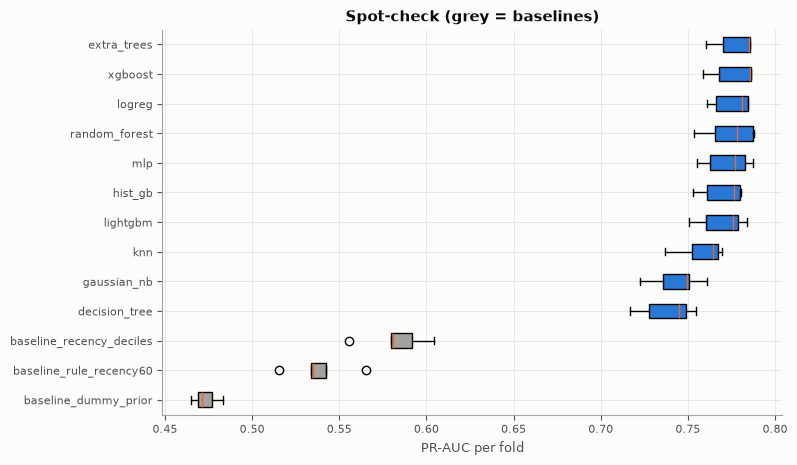

carried forward to tuning: ['extra_trees', 'xgboost']


In [9]:
spot = metric("spotcheck")
tbl = pd.DataFrame(spot["table"]).set_index("model").sort_values("pr_auc_mean", ascending=False)
display(
    tbl[
        [
            "pr_auc_mean",
            "pr_auc_std",
            "roc_auc_mean",
            "brier_mean",
            "recall_top_decile_mean",
            "fit_seconds_mean",
        ]
    ]
)

order = tbl.index[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(
    [[f["pr_auc"] for f in spot["folds"][m]] for m in order],
    orientation="horizontal",
    patch_artist=True,
)
for patch, m in zip(bp["boxes"], order, strict=True):
    patch.set_facecolor(style.NEUTRAL if m.startswith("baseline") else style.BLUE)
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_xlabel("PR-AUC per fold")
ax.set_title("Spot-check (grey = baselines)")
plt.show()
print("carried forward to tuning:", spot["top2"])

**Comment.** Every model beats the baselines by ~0.19 PR-AUC, but the top is flat: several families
are within one fold standard deviation. Features matter more than the algorithm.

### 6.2 Bayesian tuning (Optuna TPE + median pruning)

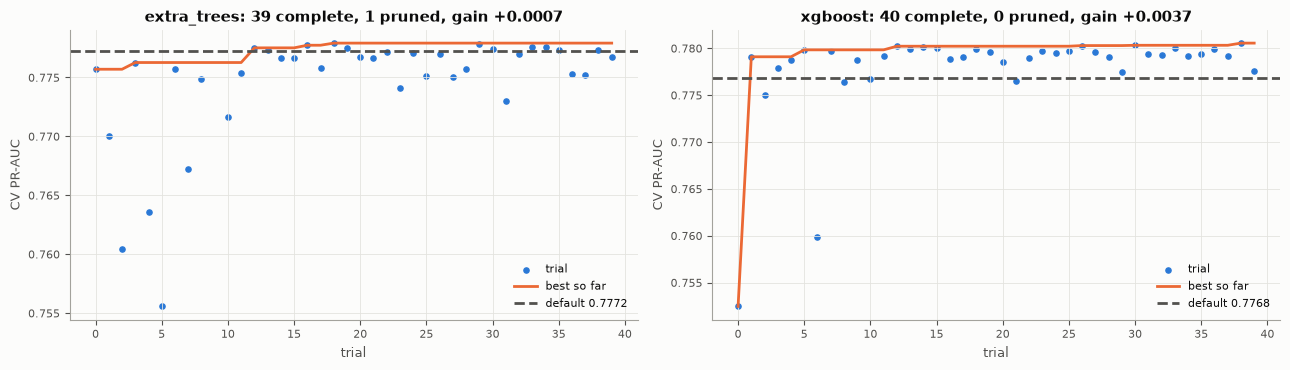

winner: xgboost -> {'n_estimators': 400, 'learning_rate': 0.024676694513176865, 'max_depth': 4, 'min_child_weight': 1.3217448695018015, 'subsample': 0.7230834417269228, 'colsample_bytree': 0.8179230582191568, 'reg_lambda': 4.898731834917197, 'reg_alpha': 1.9776200360519942, 'gamma': 3.935549645920759}


In [10]:
tuning = metric("tuning")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (name, r) in zip(axes, tuning["results"].items(), strict=True):
    hist = pd.DataFrame(r["history"])
    done = hist[hist["state"] == "COMPLETE"]
    ax.scatter(done["number"], done["value"], s=14, color=style.BLUE, label="trial")
    ax.plot(done["number"], done["value"].cummax(), color=style.ORANGE, label="best so far")
    ax.axhline(
        r["default_value"], ls="--", color=style.INK_2, label=f"default {r['default_value']:.4f}"
    )
    ax.set_title(
        f"{name}: {r['n_complete']} complete, {r['n_pruned']} pruned, gain {r['improvement']:+.4f}"
    )
    ax.set_xlabel("trial")
    ax.set_ylabel("CV PR-AUC")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("winner:", tuning["winner"], "->", tuning["results"][tuning["winner"]]["best_params"])

**Comment.** Tuning adds less than 0.004 PR-AUC — less than fold noise. Honest conclusion: the problem
is limited by the information in the features, not by hyper-parameters.

### 6.3 Calibration and the single shipped artifact

RetentionModel | 0.3.0+xgboost | calibration: sigmoid | threshold: 0.56


,brier,log_loss,ece
none,0.1884,0.5536,0.0530
sigmoid,0.1859,0.5471,0.0179
isotonic,0.1868,0.5563,0.0205


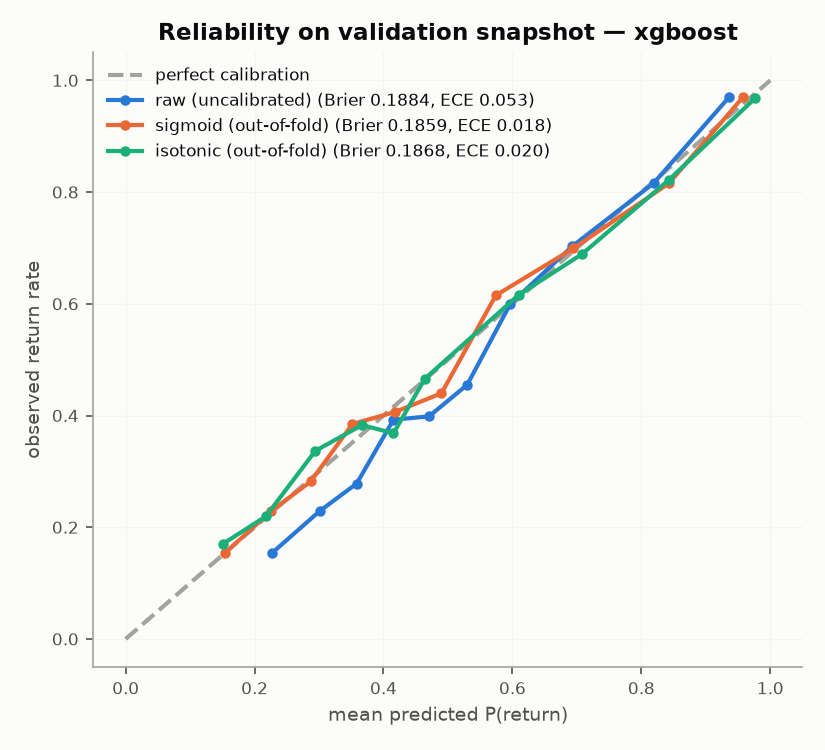

In [11]:
import joblib

model = joblib.load(paths.model_file)  # preprocessing + XGBoost + calibrator + threshold
meta = json.loads(paths.model_meta.read_text(encoding="utf-8"))
print(
    type(model).__name__,
    "|",
    meta["model_version"],
    "| calibration:",
    meta["calibration_method"],
    "| threshold:",
    meta["decision_threshold"],
)

final = metric("train_final")
cal = pd.DataFrame(final["candidates"][final["champion"]]["calibration"]).T
display(
    cal.style.format("{:.4f}").set_caption(
        "5-fold out-of-fold calibration on the validation snapshot"
    )
)
display(Image(filename=str(paths.figures / "reliability_validation.png"), width=520))

**Comment.** Sigmoid (Platt) calibration cuts the expected calibration error from 0.053 to 0.018.
It matters because the probability is multiplied by customer-specific dollar values in §6.4.

### 6.4 Threshold chosen by expected profit, not 0.5

coupon 4.0$ · discount 15% · save rate 0.2 · margin 30% · value horizon 365 d


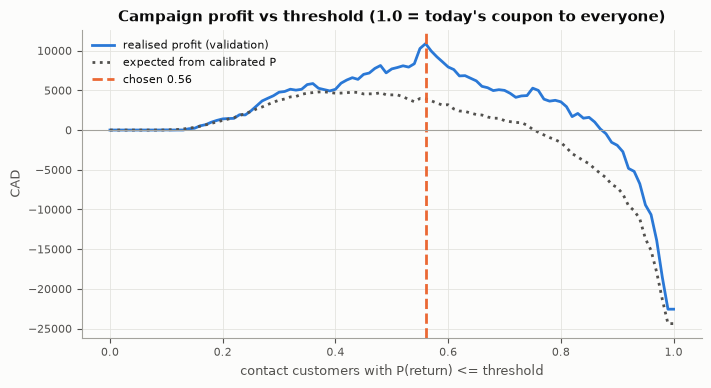

,best_threshold,max_profit
save_rate=0.10,0.0000,0.0000
save_rate=0.20,0.5600,"10,884.3125"
save_rate=0.30,0.7600,"34,881.2231"


,validation quarter
n_customers,"2,658.0000"
threshold,0.5600
model_contacted,"1,696.0000"
model_profit,"10,884.3125"
ev_policy_contacted,"1,179.0000"
ev_policy_profit,"15,024.4613"
everyone_profit,"-22,564.6044"
nobody_profit,0.0000
model_vs_everyone,"33,448.9169"
model_profit_per_1000,"4,094.9257"


In [12]:
b = params.business
print(
    f"coupon {b.coupon_cost}$ · discount {b.discount_rate:.0%} · save rate {b.save_rate} · margin {b.gross_margin:.0%} · value horizon {b.value_horizon_days} d"
)
curve = pd.DataFrame(final["profit_curve"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    curve["threshold"],
    curve["realised_profit"],
    color=style.BLUE,
    label="realised profit (validation)",
)
ax.plot(
    curve["threshold"],
    curve["expected_profit"],
    color=style.INK_2,
    ls=":",
    label="expected from calibrated P",
)
ax.axvline(
    final["threshold"], color=style.ORANGE, ls="--", label=f"chosen {final['threshold']:.2f}"
)
ax.axhline(0, color=style.NEUTRAL, lw=0.8)
ax.set_xlabel("contact customers with P(return) <= threshold")
ax.set_ylabel("CAD")
ax.legend()
ax.set_title("Campaign profit vs threshold (1.0 = today's coupon to everyone)")
plt.show()
display(pd.DataFrame(final["threshold_sensitivity"]).T)
display(pd.Series(final["validation_policy"]).to_frame("validation quarter"))

**Comment.** The blanket coupon loses money (≈ −$22.6k on the validation quarter); the chosen threshold
earns ≈ +$10.9k. The result depends on the assumed save rate: at 10% no threshold is profitable
(`threshold_sensitivity`). A first design valued a saved customer at 90 days of margin and made every
coupon unprofitable — kept as a documented negative result.

### 6.5 Held-out test results (read from the recorded evaluation, not re-scored)

In [13]:
test = metric("test_evaluation")
print(
    "test snapshot:",
    test["cutoff"],
    "· customers:",
    test["n"],
    "· base rate:",
    f"{test['positive_rate']:.1%}",
    "· looks at the test set:",
    test["n_test_looks"],
)
rows = {"model (calibrated)": test["metrics"]} | {k: v for k, v in test["baselines"].items()}
display(pd.DataFrame(rows).T[["pr_auc", "roc_auc", "brier", "recall_top_decile"]])
print("PR-AUC 95% CI:", test["ci95"]["pr_auc"])
display(pd.Series(test["policy"]).to_frame("test quarter"))

test snapshot: ['2011-09-01'] · customers: 2768 · base rate: 60.7% · looks at the test set: 2


,pr_auc,roc_auc,brier,recall_top_decile
model (calibrated),0.8504,0.7718,0.1885,0.1613
baseline_dummy_prior,0.6069,0.5000,0.2565,0.1262
baseline_rule_recency60,0.6734,0.6187,0.2439,0.1512
baseline_recency_deciles,0.7123,0.6563,0.2416,0.1315


PR-AUC 95% CI: {'lo': 0.8350480398870216, 'hi': 0.8647211412629555}


,test quarter
n_customers,"2,768.0000"
threshold,0.5600
model_contacted,"1,139.0000"
model_profit,-7.1916
ev_policy_contacted,376.0000
ev_policy_profit,"2,421.4476"
everyone_profit,"-55,176.1777"
nobody_profit,0.0000
model_vs_everyone,"55,168.9861"
model_profit_per_1000,-2.5981


### 6.6 Error analysis by segment

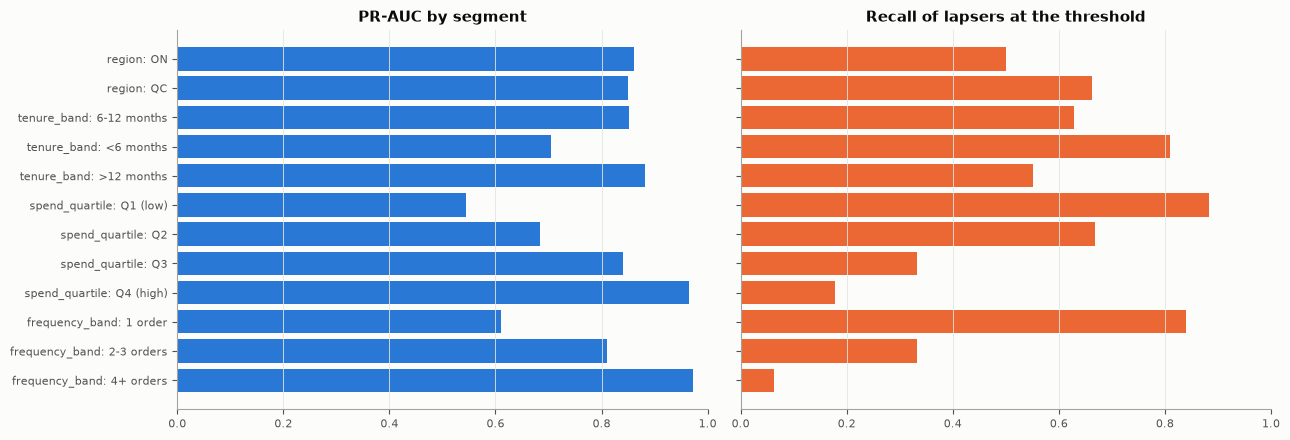

In [14]:
seg = pd.DataFrame(test["segments"]).query("n >= 50")
seg["label"] = seg["segment"] + ": " + seg["value"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].barh(seg["label"], seg["pr_auc"], color=style.BLUE)
axes[0].set_title("PR-AUC by segment")
axes[1].barh(seg["label"], seg["lapse_recall"], color=style.ORANGE)
axes[1].set_title("Recall of lapsers at the threshold")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

**Comment.** The model is weak for one-order and low-spend customers (little history), and a single
probability threshold rarely selects *high-spend* lapsers — the most valuable ones. Next steps:
per-customer expected-value targeting and the D5 fairness audit (> 5-point recall gaps).

## 7. Head B — association rules (mined offline, served by lookup)

In [15]:
from boreal_marche.recommend.engine import RuleEngine

engine = RuleEngine.from_json(paths.rules_file, min_lift=params.recommend.min_lift)
h = engine.header
print(f"{h['rule_count']:,} rules · mined {h['mined_at']} · params {h['params']}")
rules_df = pd.DataFrame(
    [
        {
            "antecedent": " + ".join(engine.catalogue.get(a, a) for a in sorted(r.antecedent)),
            "consequent": engine.catalogue.get(r.consequent, r.consequent),
            "support": r.support,
            "confidence": r.confidence,
            "lift": r.lift,
        }
        for r in engine.rules
    ]
)
display(rules_df.sort_values("lift", ascending=False).head(8))

mining = metric("rules_mining")
print(
    "dense vs sparse basket matrix (MB):",
    round(mining["memory"]["dense_bool_mb"], 1),
    "vs",
    round(mining["memory"]["sparse_csr_mb"], 1),
)
print(
    "Apriori s:",
    round(mining["apriori_seconds"], 1),
    "| FP-Growth s:",
    round(mining["fpgrowth_seconds"], 1),
)
print(
    "lift trap (discarded):",
    mining["lift_trap_example"]["antecedent_desc"],
    "->",
    mining["lift_trap_example"]["consequent_desc"],
    f"conf {mining['lift_trap_example']['confidence']:.1%}, lift {mining['lift_trap_example']['lift']:.2f}",
)

7,512 rules · mined 2026-09-29T18:51:15+00:00 · params {'min_support': 0.005, 'min_confidence': 0.2, 'min_lift': 3.0, 'max_len': 3, 'rank_by': 'confidence', 'single_item_consequents': True}


,antecedent,consequent,support,confidence,lift
0,HERB MARKER THYME + HERB MARKER PARSLEY,HERB MARKER CHIVES,0.0050,0.8663,151.2559
1,HERB MARKER THYME + HERB MARKER CHIVES,HERB MARKER PARSLEY,0.0050,0.9643,150.3818
2,HERB MARKER THYME + HERB MARKER MINT,HERB MARKER ROSEMARY,0.0053,0.9500,148.8766
3,HERB MARKER ROSEMARY + HERB MARKER PARSLEY,HERB MARKER THYME,0.0055,0.9565,148.4503
4,HERB MARKER PARSLEY + HERB MARKER CHIVES,HERB MARKER THYME,0.0050,0.9529,147.8946
5,HERB MARKER THYME + HERB MARKER PARSLEY,HERB MARKER ROSEMARY,0.0055,0.9412,147.4938
6,HERB MARKER THYME + HERB MARKER BASIL,HERB MARKER ROSEMARY,0.0054,0.9402,147.3435
7,HERB MARKER THYME + HERB MARKER MINT,HERB MARKER PARSLEY,0.0053,0.9444,147.2875


dense vs sparse basket matrix (MB): 136.8 vs 3.8
Apriori s: 1.6 | FP-Growth s: 214.8
lift trap (discarded): ['HEART FILIGREE DOVE SMALL'] -> WHITE HANGING HEART T-LIGHT HOLDER conf 44.7%, lift 3.00


In [16]:
# Live serving: three documented strategies.
for basket in ([], ["NOT-A-SKU"], ["22916", "22918"], ["85123A", "22423"]):
    res = engine.recommend(basket, k=3)
    print(f"\nbasket={basket} -> strategy={res.strategy}")
    for r in res.recommendations:
        why = (
            f"because {sorted(r.rule.antecedent)} (lift {r.rule.lift:.1f})"
            if r.rule
            else "best-seller"
        )
        print(f"   {r.item:<8} {r.description[:38]:<38} {why}")


basket=[] -> strategy=empty_basket
   85123A   WHITE HANGING HEART T-LIGHT HOLDER     best-seller
   22423    REGENCY CAKESTAND 3 TIER               best-seller
   85099B   JUMBO BAG RED RETROSPOT                best-seller

basket=['NOT-A-SKU'] -> strategy=popularity_fallback
   85123A   WHITE HANGING HEART T-LIGHT HOLDER     best-seller
   22423    REGENCY CAKESTAND 3 TIER               best-seller
   85099B   JUMBO BAG RED RETROSPOT                best-seller

basket=['22916', '22918'] -> strategy=rules
   22917    HERB MARKER ROSEMARY                   because ['22916', '22918'] (lift 147.5)
   22920    HERB MARKER BASIL                      because ['22916', '22918'] (lift 139.7)
   22919    HERB MARKER MINT                       because ['22916', '22918'] (lift 139.7)

basket=['85123A', '22423'] -> strategy=rules
   21212    PACK OF 72 RETROSPOT CAKE CASES        because ['22423', '85123A'] (lift 3.5)
   47566    PARTY BUNTING                          because ['22423', '85123A']

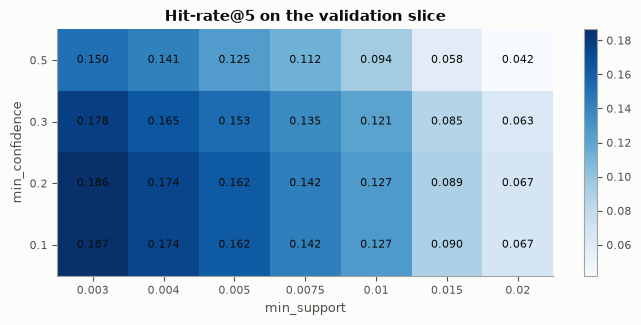

,holdout
n_cases,"6,897.0000"
hit_rate_rules_only,0.1431
hit_rate_hybrid,0.1446
hit_rate_popularity,0.0168
hybrid_vs_popularity_ratio,8.5948
basket_coverage,0.9172
catalogue_coverage,0.1012


In [17]:
sweep = pd.DataFrame(metric("rules_sweep")["table"])
sub = sweep.query("min_lift == @params.recommend.min_lift and rank_by == 'confidence'")
pivot = sub.pivot(index="min_confidence", columns="min_support", values="hit_rate_hybrid")
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(pivot.values, cmap="Blues", aspect="auto", origin="lower")
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.iat[i, j]:.3f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("min_support")
ax.set_ylabel("min_confidence")
ax.grid(False)
ax.set_title("Hit-rate@5 on the validation slice")
fig.colorbar(im, ax=ax)
plt.show()

ev = metric("rules_evaluation")
display(
    pd.Series(
        {
            k: ev[k]
            for k in [
                "n_cases",
                "hit_rate_rules_only",
                "hit_rate_hybrid",
                "hit_rate_popularity",
                "hybrid_vs_popularity_ratio",
                "basket_coverage",
                "catalogue_coverage",
            ]
        }
    ).to_frame("holdout")
)

**Comment.** Rules beat the best-seller baseline 8.6× on the temporal holdout and fire for 92% of
baskets. Lower support keeps improving hit-rate but multiplies rules and mining time; 0.005 is the
chosen trade-off. Surprise worth reporting: in mlxtend, Apriori is far faster than FP-Growth here.

## 8. The typed API, called in-process (FastAPI TestClient)

In [18]:
from fastapi.testclient import TestClient

from boreal_marche.api import app

val = gold[gold["split"] == "validation"].iloc[0]  # a validation customer (not the test snapshot)
features = {
    k: (None if pd.isna(v) else (v.item() if hasattr(v, "item") else v))
    for k, v in val[FEATURES].items()
}
with TestClient(app) as client:
    print("GET /ready    ->", client.get("/ready").json())
    print("GET /version  ->", client.get("/version").json())
    print(
        "POST /predict ->",
        client.post("/predict", json={"customer_ref": "demo", "features": features}).json(),
    )
    print(
        "POST /predict with an extra field -> HTTP",
        client.post("/predict", json={"features": features, "x": 1}).status_code,
    )
    print(
        "POST /recommend ->",
        client.post("/recommend", json={"basket": ["22916"], "k": 2}).json()["strategy"],
    )

GET /ready    -> {'ready': True, 'model_loaded': True, 'rules_loaded': True, 'errors': []}
GET /version  -> {'api_version': '0.3.0', 'git_commit': 'a803635a95302521a822367dddea6c36f28f354e-dirty', 'model_version': '0.3.0+xgboost', 'model_source': 'artifacts/model.joblib', 'rules_mined_at': '2026-09-29T18:51:15+00:00', 'rule_count': 7512}
POST /predict -> {'customer_ref': 'demo', 'p_return': 0.5622161874691924, 'send_coupon': False, 'threshold': 0.56, 'model_version': '0.3.0+xgboost'}
POST /predict with an extra field -> HTTP 422
POST /recommend -> rules


/home/master/AI/projects/boreal-marche-capstone/.venv/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


## 9. MLflow tracking summary

In [19]:
db = ROOT / "mlflow.db"
if db.exists():
    import sqlite3

    with sqlite3.connect(db) as con:
        runs = pd.read_sql(
            "select e.name as experiment, count(*) as runs from runs r join experiments e "
            "on r.experiment_id = e.experiment_id group by e.name",
            con,
        )
        versions = pd.read_sql("select name, version, current_stage from model_versions", con)
        aliases = pd.read_sql("select * from registered_model_aliases", con)
    display(runs)
    display(versions)
    display(aliases)
else:
    print("mlflow.db not found — run the pipeline first (python scripts/run.py all)")

,experiment,runs
0,boreal-recommend,1
1,boreal-retention,98


,name,version,current_stage
0,boreal-retention,1,None
1,boreal-retention,2,None


,alias,version,name
0,champion,1,boreal-retention
1,challenger,2,boreal-retention


## Summary and next steps

* **Data:** reproducible, checksummed, 11 counted cleaning rules; sheet-overlap bug found and fixed.
* **Head A:** test PR-AUC 0.850 vs 0.712 best heuristic; calibrated; profit-based threshold; honest limits.
* **Head B:** 7,512 rules, hit-rate@5 0.145 vs 0.017 popularity; explainable recommendations.
* **Engineering:** typed API, tests, CI, Docker, MLflow registry, reproducible fresh clone.

Next (weeks 9–15): Head C (RAG assistant, 40-question golden set), deployment with CI/CD, the
five-section interface, monitoring and drift alerts, fairness audit and the Law 25 file.